# Sprint 2 — Exploratory Data Analysis & Visualization
## Bank Marketing Campaign & Customer Response Analytics

**Sprint goal:** find meaningful customer, campaign and financial patterns associated with a customer subscribing to the term deposit (`deposit = yes`), and show what they mean for the bank.

### Three data layers used in this notebook (kept separate)
| Layer | Source | Nature |
|---|---|---|
| **Core banking data** | `bank_core_cleaned.csv` (output of Sprint 1) | Real customer and campaign records, 11,162 rows |
| **ROI proxy** | `bank_roi_proxy.csv` | **Assumption-based**: cost = 0.50 per call-minute, value = 200 per subscriber. Illustrative only, *not* bank financials |
| **Campaign performance table** | `Marketing Campaign Performance and ROI Dataset.xlsx` | Real campaign-level Spend / Clicks / Revenue for 88 campaigns. Has **no customer key**, so it is analysed separately and never merged into customer rows |

### How to read the results
* **Response rate** = share of customers in a group who subscribed. The overall baseline is **47.4%**; every segment is compared with it.
* Every chart is followed by **Observation** (what is shown), **Interpretation** (what it means) and **Business insight** (why the bank should care).
* All findings are *associations*, not causes. Statistical validation (chi-square, t-test, ANOVA, confidence intervals) is the job of Sprint 3.
* Important caveat: `duration` is only known **after** a call ends, so it can describe call quality but cannot be used to choose whom to call.

## 0. Setup and joining the two customer-level tables

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 30)

DATA_DIR = '.'   # folder holding bank_core_cleaned.csv, bank_roi_proxy.csv and the campaign xlsx
core = pd.read_csv(f'{DATA_DIR}/bank_core_cleaned.csv')
roi  = pd.read_csv(f'{DATA_DIR}/bank_roi_proxy.csv')

# Real banking data + assumption-based ROI proxy, joined on the shared key (1 row per customer in both)
df = core.merge(roi, on='customer_id', how='inner', validate='one_to_one')
print('core:', core.shape, '| roi proxy:', roi.shape, '| merged:', df.shape)

month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
df['month'] = pd.Categorical(df['month'], categories=month_order, ordered=True)
df['deposit_flag'] = (df['deposit'] == 'yes').astype(int)      # 1 = subscribed
BASE = df['deposit_flag'].mean() * 100
print(f'\nBaseline response rate (all customers): {BASE:.1f}%  ->  every segment below is compared against this number')

core: (11162, 18) | roi proxy: (11162, 6) | merged: (11162, 23)

Baseline response rate (all customers): 47.4%  ->  every segment below is compared against this number


**Observation:** the core table (18 columns) and the ROI proxy table (6 columns) both have 11,162 rows and join one-to-one on `customer_id` (`validate='one_to_one'` would have raised an error otherwise). 47.4% of customers subscribed.

**Interpretation / insight:** the target is close to balanced, so response-rate comparisons between segments are meaningful and are not distorted by a rare positive class.

## 1. Descriptive analysis

In [2]:
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
d = df[num_cols].describe(percentiles=[.05, .25, .5, .75, .95, .99]).T
d['skew'] = df[num_cols].skew()
d['cv_%'] = (df[num_cols].std() / df[num_cols].mean() * 100)
print(d.round(1).to_string())
print('\nMean vs median gap (positive = right-skewed):')
print((df[num_cols].mean() - df[num_cols].median()).round(1).to_string())

            count    mean     std     min    5%    25%    50%     75%     95%      99%      max  skew   cv_%
age       11162.0    41.2    11.8    18.0  26.0   32.0   39.0    49.0    61.0     77.0     95.0   0.9   28.7
balance   11162.0  1519.7  3215.9 -6847.0 -49.9  127.0  551.0  1693.0  6004.9  13107.0  81204.0   8.3  211.6
duration  11162.0   370.5   345.1     2.0  52.0  139.0  255.0   490.0  1074.0   1574.8   3881.0   2.2   93.1
campaign  11162.0     2.5     2.7     1.0   1.0    1.0    2.0     3.0     7.0     13.0     63.0   5.5  108.5
pdays     11162.0    51.3   108.8    -1.0  -1.0   -1.0   -1.0    20.8   326.0    425.4    854.0   2.4  211.9
previous  11162.0     0.8     2.3     0.0   0.0    0.0    0.0     1.0     5.0     10.0     58.0   7.3  275.3

Mean vs median gap (positive = right-skewed):
age           2.2
balance     968.7
duration    115.5
campaign      0.5
pdays        52.3
previous      0.8


**Observation**
* `age`: median 39, mean 41.2, mild right skew (0.9); middle 50% of customers are 32–49.
* `balance`: median **551** but mean **1,520**, skew **8.3**; 25% of customers hold under 127 and the 95th percentile is about 6,005. The coefficient of variation is 212%.
* `duration`: median 255 s (about 4 min), mean 371 s, 95th percentile 1,074 s (about 18 min).
* `campaign`: median 2 contacts, 99th percentile 13, maximum 63 (after the Sprint 1 correction).
* `pdays`: the median is −1, i.e. most customers were never contacted before; `previous` is 0 for the typical customer (median 0).

**Interpretation:** balance, duration, campaign and previous are all strongly right-skewed: a few very large values pull the mean far above the typical customer. The **median** is the honest "typical customer" measure for these columns.

**Business insight:** the typical customer is mainstream (around 39 years old, about 550 in the account, one or two calls of about 4 minutes). Averages overstate wealth and effort, so reports to management should quote medians or percentiles.

## 2. Univariate analysis

### 2.1 Numerical features

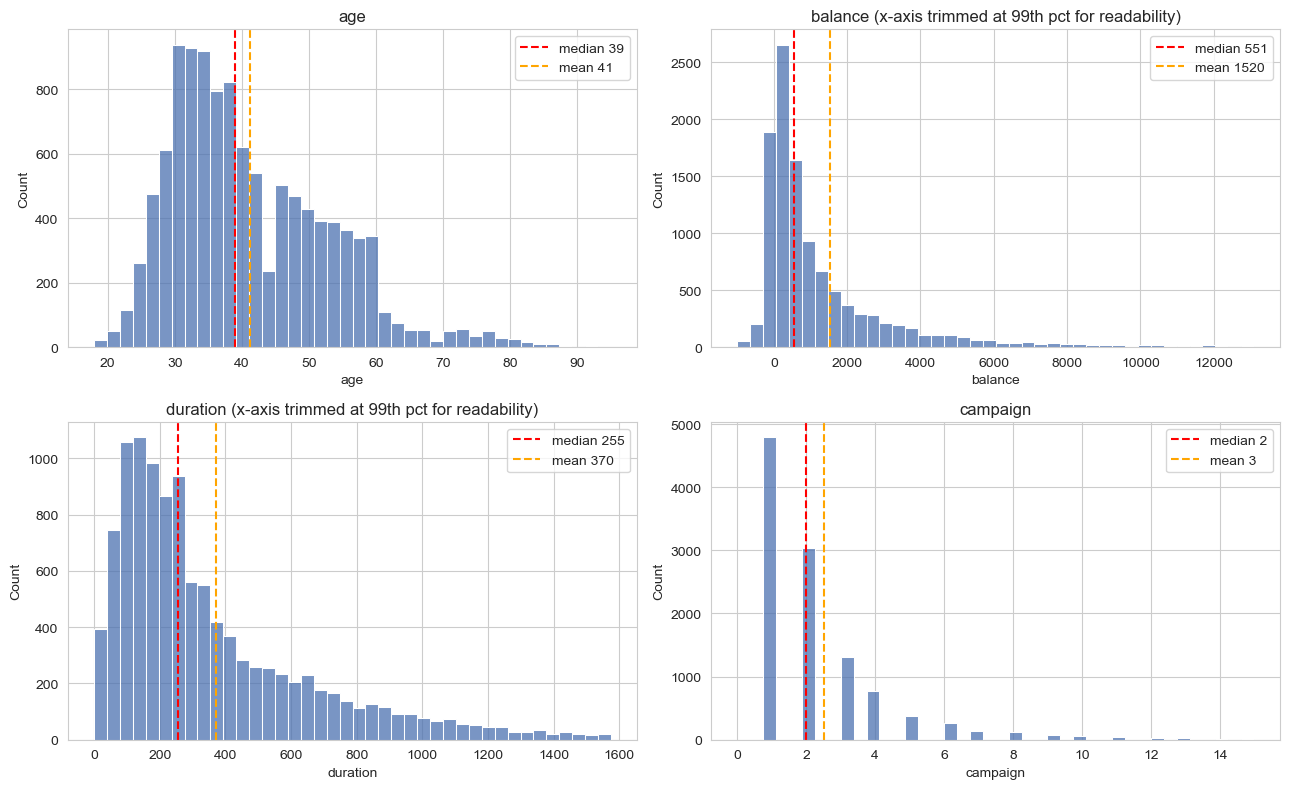

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
specs = [('age', None), ('balance', (-1000, df.balance.quantile(.99))), ('duration', (0, df.duration.quantile(.99))), ('campaign', (0, 15))]
for ax, (c, rng) in zip(axes.flat, specs):
    sns.histplot(df[c], bins=40, binrange=rng, ax=ax, color='#4C72B0')
    ax.axvline(df[c].median(), color='red', ls='--', label=f'median {df[c].median():.0f}')
    ax.axvline(df[c].mean(), color='orange', ls='--', label=f'mean {df[c].mean():.0f}')
    ax.set_title(c + (' (x-axis trimmed at 99th pct for readability)' if rng and c != 'campaign' else ''))
    ax.legend()
plt.tight_layout(); plt.show()

**Observation:** age is unimodal with a long right tail; balance, duration and campaign pile up near the low end with long tails, and the mean (orange) sits well right of the median (red).

**Interpretation:** the shape confirms the skew statistics above. No variable is normally distributed, which matters for Sprint 3: rank-based or log-based methods are safer than methods assuming normality.

**Business insight:** campaign effort is concentrated on 1–3 calls per customer, but a visible tail receives many more; later sections test whether extra calls pay off.

### 2.2 Categorical features

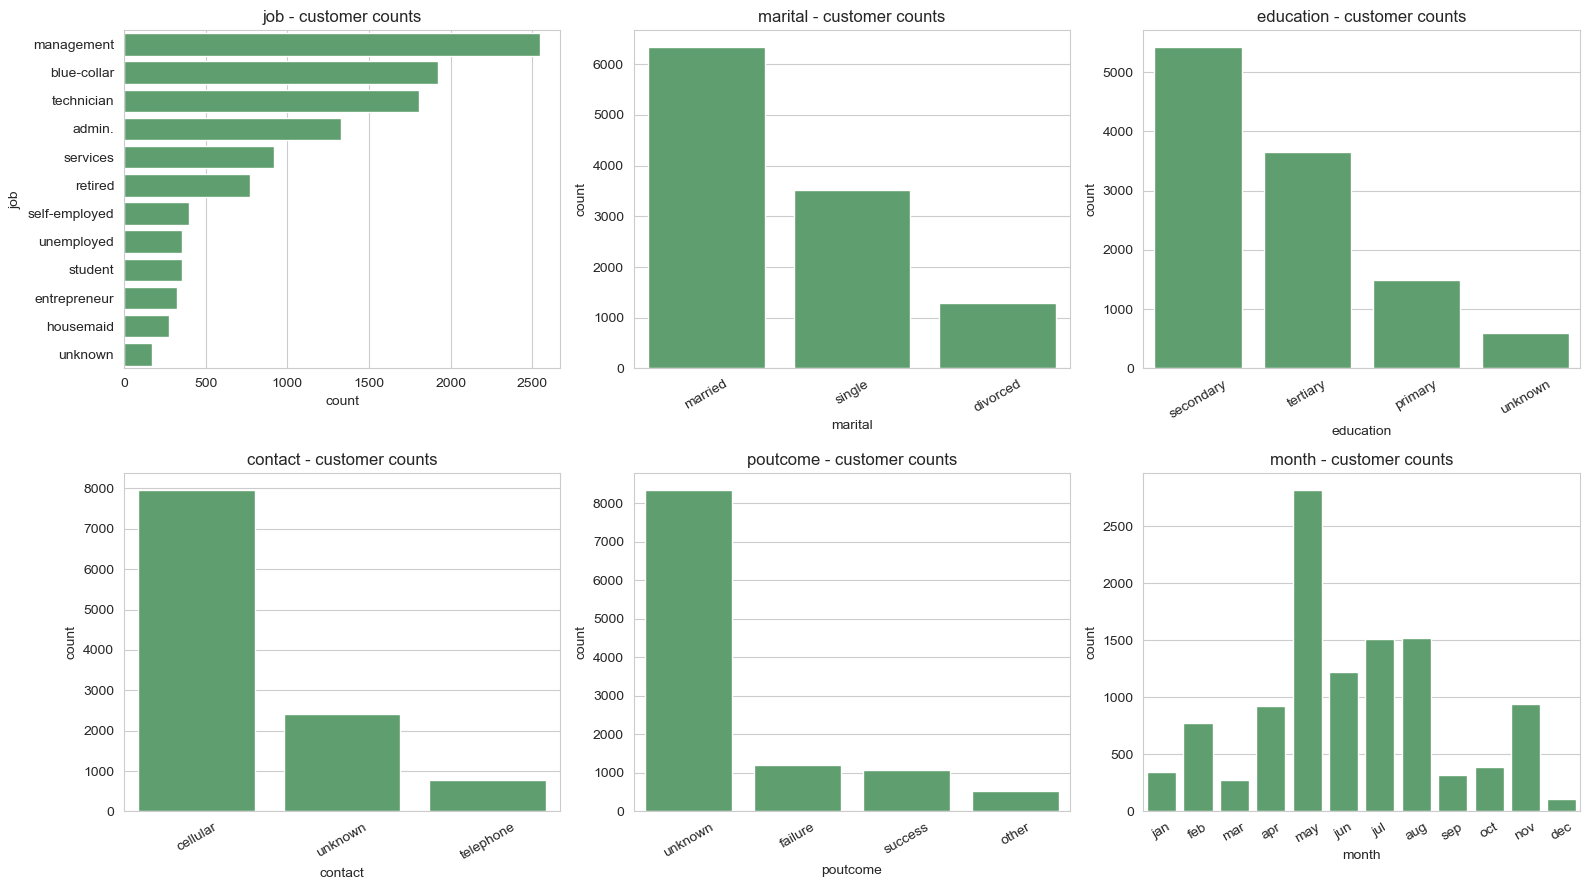


job: {'management': 22.8, 'blue-collar': 17.2, 'technician': 16.2, 'admin.': 11.9, 'services': 8.2, 'retired': 6.9, 'self-employed': 3.6, 'unemployed': 3.2, 'student': 3.2, 'entrepreneur': 2.9, 'housemaid': 2.5, 'unknown': 1.5}

marital: {'married': 56.9, 'single': 31.5, 'divorced': 11.6}

education: {'secondary': 48.7, 'tertiary': 32.7, 'primary': 13.3, 'unknown': 5.3}

contact: {'cellular': 71.4, 'unknown': 21.7, 'telephone': 6.9}

poutcome: {'unknown': 74.9, 'failure': 10.9, 'success': 9.5, 'other': 4.7}

housing: {'no': 52.7, 'yes': 47.3}

loan: {'no': 86.9, 'yes': 13.1}

default: {'no': 98.5, 'yes': 1.5}


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flat, ['job', 'marital', 'education', 'contact', 'poutcome', 'month']):
    order = df[c].value_counts().index if c != 'month' else month_order
    sns.countplot(data=df, y=c if c in ('job',) else None, x=None if c in ('job',) else c, order=order, ax=ax, color='#55A868')
    ax.set_title(f'{c} - customer counts')
    if c != 'job': ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
for c in ['job', 'marital', 'education', 'contact', 'poutcome', 'housing', 'loan', 'default']:
    print(f'\n{c}:', (df[c].value_counts(normalize=True) * 100).round(1).to_dict())

**Observation**
* Jobs: management (22.8%), blue-collar (17.2%) and technician (16.2%) make up over half of the base; `unknown` is only 1.5%.
* 56.9% are married; secondary education dominates (48.7%), with tertiary 32.7%.
* Contact: cellular 71.4%, **unknown 21.7%**, telephone 6.9%.
* Previous outcome: **74.9% unknown** (no earlier campaign). 47.3% hold a housing loan, 13.1% a personal loan and only 1.5% are in default.
* **May alone accounts for 2,824 contacts (25% of the whole campaign)**; December has only 110.

**Interpretation:** this is a mainstream, cellular-reachable customer base, and most customers are new to the campaign. Campaign volume is highly uneven across months.

**Business insight:** (1) results for rare groups (default = yes, `unknown` job, December) rest on small samples and need caution; (2) the heavy May concentration will matter when reading monthly response rates in section 3.4.

## 3. Bivariate analysis — what is associated with subscribing?

### 3.1 Categorical features vs response rate

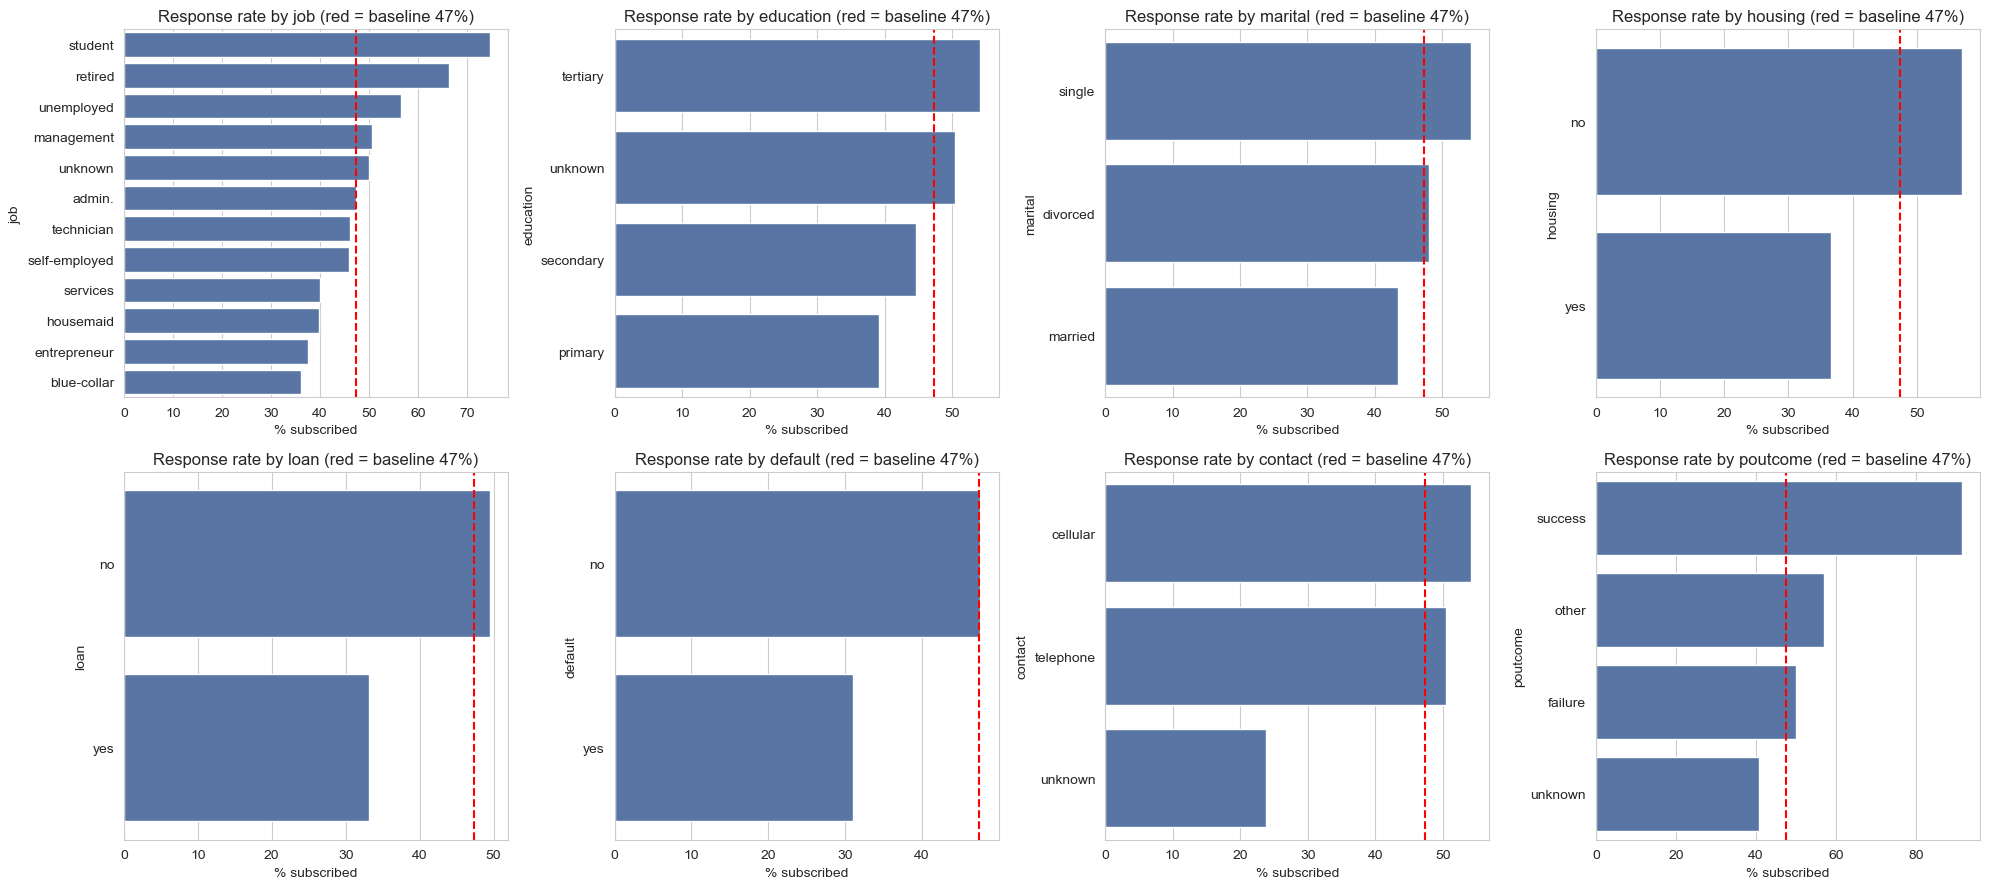


--- job ---
               customers  response_rate_pct
job                                        
student              356               74.7
retired              771               66.4
unemployed           357               56.6
management          2544               50.7
unknown              170               50.0
admin.              1326               47.3
technician          1803               46.1
self-employed        401               45.9
services             917               40.0
housemaid            274               39.8
entrepreneur         322               37.6
blue-collar         1921               36.1

--- education ---
           customers  response_rate_pct
education                              
tertiary        3651               54.2
unknown          592               50.5
secondary       5431               44.7
primary         1488               39.2

--- marital ---
          customers  response_rate_pct
marital                               
single         35

In [5]:
def rate_table(col, data=df):
    t = data.groupby(col, observed=True)['deposit_flag'].agg(customers='size', response_rate_pct=lambda s: s.mean() * 100).round(1)
    return t.sort_values('response_rate_pct', ascending=False)

cats = ['job', 'education', 'marital', 'housing', 'loan', 'default', 'contact', 'poutcome']
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.flat, cats):
    t = rate_table(c)
    sns.barplot(x=t.response_rate_pct.values, y=t.index.astype(str), ax=ax, color='#4C72B0')
    ax.axvline(BASE, color='red', ls='--'); ax.set_title(f'Response rate by {c} (red = baseline {BASE:.0f}%)'); ax.set_xlabel('% subscribed')
plt.tight_layout(); plt.show()
for c in cats:
    print(f'\n--- {c} ---'); print(rate_table(c).to_string())

**Observation** (response rate; baseline 47.4%)
* **Job:** student 74.7% and retired 66.4% lead; unemployed 56.6%; blue-collar 36.1% and entrepreneur 37.6% are lowest.
* **Education:** tertiary 54.2% vs primary 39.2%.  **Marital:** single 54.3% vs married 43.4%.
* **Housing loan:** no 57.0% vs yes 36.6%.  **Personal loan:** no 49.5% vs yes 33.2%.  **Default:** yes 31.0% (only 168 customers).
* **Contact:** cellular 54.2%, telephone 50.5%, **unknown 23.8%**.
* **Previous outcome:** **success 91.3%**, other 57.0%, failure 49.9%, unknown 40.8%.

**Interpretation:** the pattern is consistent with financial capacity and engagement: customers without loan commitments, with higher education, and with a positive history respond more. Past success is by far the strongest single signal, and even a past *failure* (49.9%) responds slightly above the baseline.

**Business insight:** a previous successful customer is nearly a sure conversion (91%), so these customers should be called first. Customers with a housing loan respond about 20 points less than those without, which suggests the product pitch should be adapted to them or they should be lower in the call order.

**Caution:** job, education and marital status overlap (for example, 58% of tertiary-educated customers are in management, section 7), so these effects are not independent of each other.

### 3.2 Numerical features by outcome

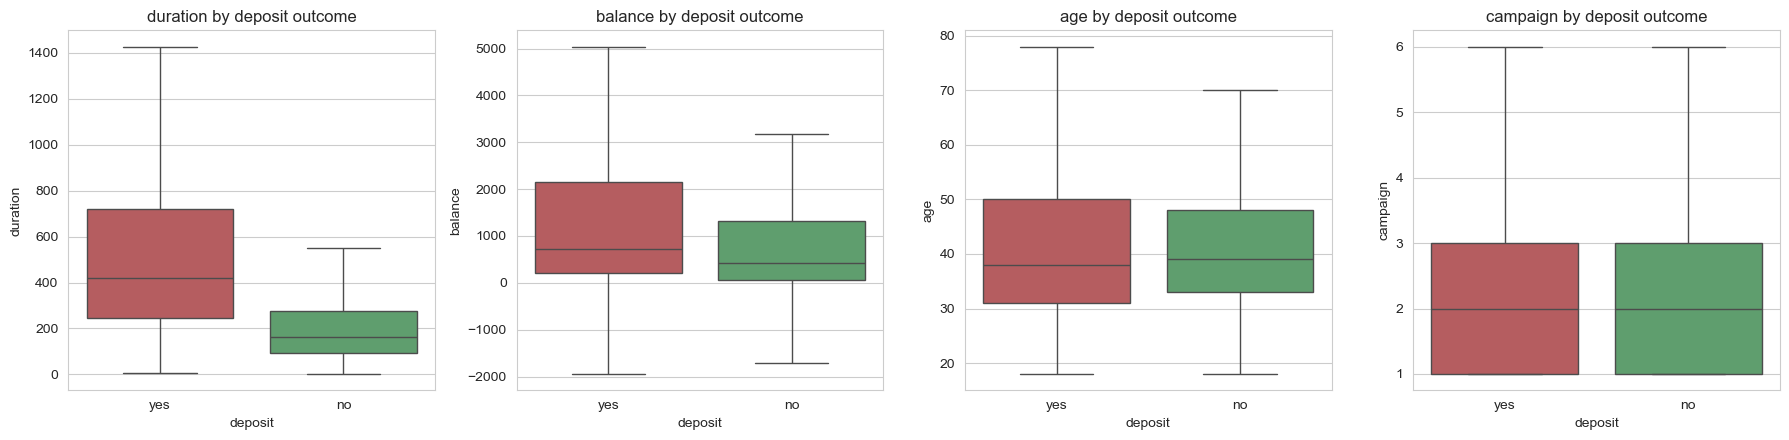

         duration  balance   age  campaign
deposit                                   
no          165.0    431.0  39.0       2.0
yes         418.0    718.0  38.0       2.0

Means:
         duration  balance   age  campaign
deposit                                   
no          223.4   1270.3  40.8       2.8
yes         533.8   1796.7  41.6       2.1


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, c in zip(axes, ['duration', 'balance', 'age', 'campaign']):
    sns.boxplot(data=df, x='deposit', y=c, showfliers=False, ax=ax, palette=['#C44E52', '#55A868'], hue='deposit', legend=False)
    ax.set_title(f'{c} by deposit outcome')
plt.tight_layout(); plt.show()
print(df.groupby('deposit')[['duration', 'balance', 'age', 'campaign']].median().round(1))
print('\nMeans:'); print(df.groupby('deposit')[['duration', 'balance', 'age', 'campaign']].mean().round(1))

**Observation:** subscribers talk for far longer (median **418 s vs 165 s**) and hold higher balances (median 718 vs 431; mean 1,797 vs 1,270). Age is almost identical (median 38 vs 39). The mean number of contacts is lower for subscribers (2.1 vs 2.8), though the medians are equal at 2.

**Interpretation:** duration separates the two groups most clearly. Balance shows a modest positive shift. Age alone does not separate subscribers from non-subscribers (the age effect appears only after grouping, see 3.3).

**Business insight:** a call that is cut short in the first two minutes almost never ends in a sale (section 3.3). Call quality is therefore a lever worth coaching, but remember duration is an outcome-correlated measure, not a pre-call targeting variable.

### 3.3 Customer and call characteristics grouped into bands

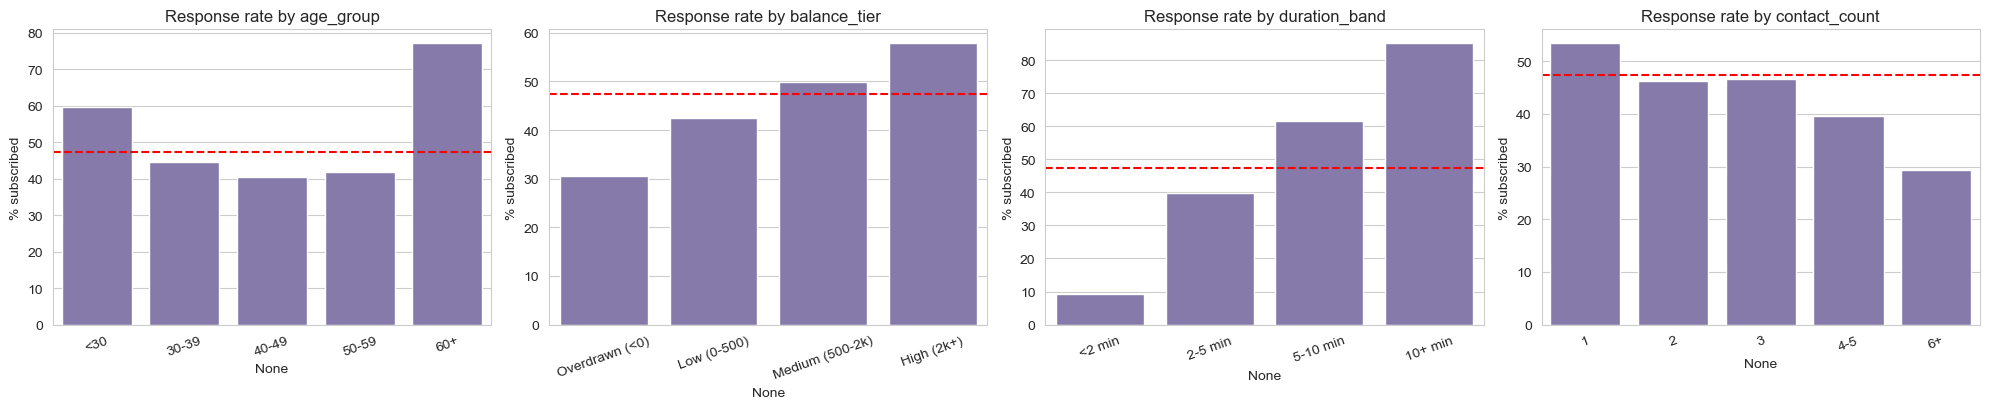


--- age_group ---
       customers  response_rate_pct
<30         1531               59.7
30-39       4406               44.4
40-49       2607               40.5
50-59       1849               41.8
60+          769               77.0

--- balance_tier ---
                 customers  response_rate_pct
Overdrawn (<0)         679               30.5
Low (0-500)           4598               42.5
Medium (500-2k)       3469               49.9
High (2k+)            2416               57.8

--- duration_band ---
          customers  response_rate_pct
<2 min         2261                9.3
2-5 min        4164               39.8
5-10 min       2611               61.7
10+ min        2126               85.1

--- contact_count ---
     customers  response_rate_pct
1         4794               53.4
2         3037               46.3
3         1318               46.7
4-5       1149               39.7
6+         864               29.3

--- debt_status ---
                         customers  response_ra

In [7]:
df['age_group'] = pd.cut(df.age, [17, 29, 39, 49, 59, 100], labels=['<30', '30-39', '40-49', '50-59', '60+'])
df['balance_tier'] = pd.cut(df.balance, [-np.inf, -1, 500, 2000, np.inf], labels=['Overdrawn (<0)', 'Low (0-500)', 'Medium (500-2k)', 'High (2k+)'])
df['duration_band'] = pd.cut(df.duration, [0, 120, 300, 600, np.inf], labels=['<2 min', '2-5 min', '5-10 min', '10+ min'])
df['contact_count'] = pd.cut(df.campaign, [0, 1, 2, 3, 5, np.inf], labels=['1', '2', '3', '4-5', '6+'])
df['debt_status'] = np.select([(df.housing == 'yes') & (df.loan == 'yes'), df.housing == 'yes', df.loan == 'yes'],
                              ['Housing + personal loan', 'Housing loan only', 'Personal loan only'], default='No loans')

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, c in zip(axes, ['age_group', 'balance_tier', 'duration_band', 'contact_count']):
    t = rate_table(c).reindex(df[c].cat.categories)
    sns.barplot(x=t.index.astype(str), y=t.response_rate_pct.values, ax=ax, color='#8172B2')
    ax.axhline(BASE, color='red', ls='--'); ax.set_title(f'Response rate by {c}'); ax.set_ylabel('% subscribed')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
for c in ['age_group', 'balance_tier', 'duration_band', 'contact_count']:
    print(f'\n--- {c} ---'); print(rate_table(c).reindex(df[c].cat.categories).to_string())
print('\n--- debt_status ---'); print(rate_table('debt_status').to_string())

**Observation**
* **Age is U-shaped:** under 30 → 59.7%, 30–39 → 44.4%, 40–49 → 40.5%, 50–59 → 41.8%, **60+ → 77.0%**.
* **Balance:** response rises steadily from **30.5%** (overdrawn) to **57.8%** (balance above 2,000).
* **Call duration:** <2 min → **9.3%**, 2–5 min → 39.8%, 5–10 min → 61.7%, **10+ min → 85.1%**.
* **Contacts in this campaign:** 1 call → 53.4%, then falling to **29.3% for 6+ calls**.
* **Debt status:** no loans 59.6%, housing only 37.6%, personal only 35.0%, both 31.7%.

**Interpretation:** the U-shape in age is largely a job effect: students (median age 25) and retirees (median age 63) are the most responsive groups (section 5). Balance and debt both point to disposable financial capacity. The fall in response with more contacts is an **association**: customers who keep saying no are the ones who get called again, so extra calls are not shown to *cause* lower response.

**Business insight:** repeated calling beyond 3 contacts is paired with sharply lower conversion (about 40% at 4–5 calls and 29% at 6+). A contact cap, or a switch to a different channel after the third attempt, is worth testing.

### 3.4 Timing: campaign volume vs response rate by month

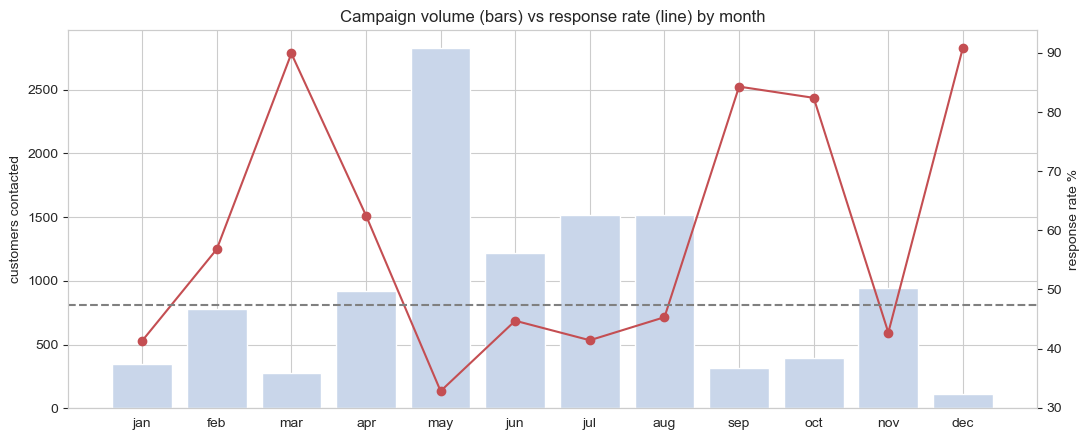

month            jan    feb    mar    apr     may     jun     jul     aug    sep    oct    nov    dec
customers      344.0  776.0  276.0  923.0  2824.0  1222.0  1514.0  1519.0  319.0  392.0  943.0  110.0
response_rate   41.3   56.8   89.9   62.5    32.8    44.7    41.4    45.3   84.3   82.4   42.7   90.9


In [8]:
m = df.groupby('month', observed=True).agg(customers=('deposit_flag', 'size'), response_rate=('deposit_flag', lambda s: s.mean() * 100)).round(1)
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(m.index.astype(str), m.customers, color='#C9D6EA'); ax1.set_ylabel('customers contacted')
ax2 = ax1.twinx(); ax2.plot(m.index.astype(str), m.response_rate, color='#C44E52', marker='o'); ax2.set_ylabel('response rate %')
ax2.axhline(BASE, color='grey', ls='--'); ax1.set_title('Campaign volume (bars) vs response rate (line) by month'); ax2.grid(False)
plt.tight_layout(); plt.show()
print(m.T.to_string())

**Observation:** response is highest in low-volume months (March 89.9%, September 84.3%, October 82.4%, December 90.9%) and lowest in the busiest month, **May (2,824 contacts, 32.8%)**. June–August and November sit in the 41–45% range.

**Interpretation:** volume and response move in opposite directions. This does *not* prove that month drives response: May and June also hold 92% of all `unknown`-contact records (1,425 + 814 of 2,423), so month, contact method and campaign intensity are tangled together and this dataset cannot separate them.

**Business insight:** the bank pushed its largest volume into its weakest-converting month. A smaller, more targeted May campaign (or moving effort into the high-response months) is a hypothesis worth testing, but it cannot be concluded from observational data alone.

## 4. Multivariate analysis

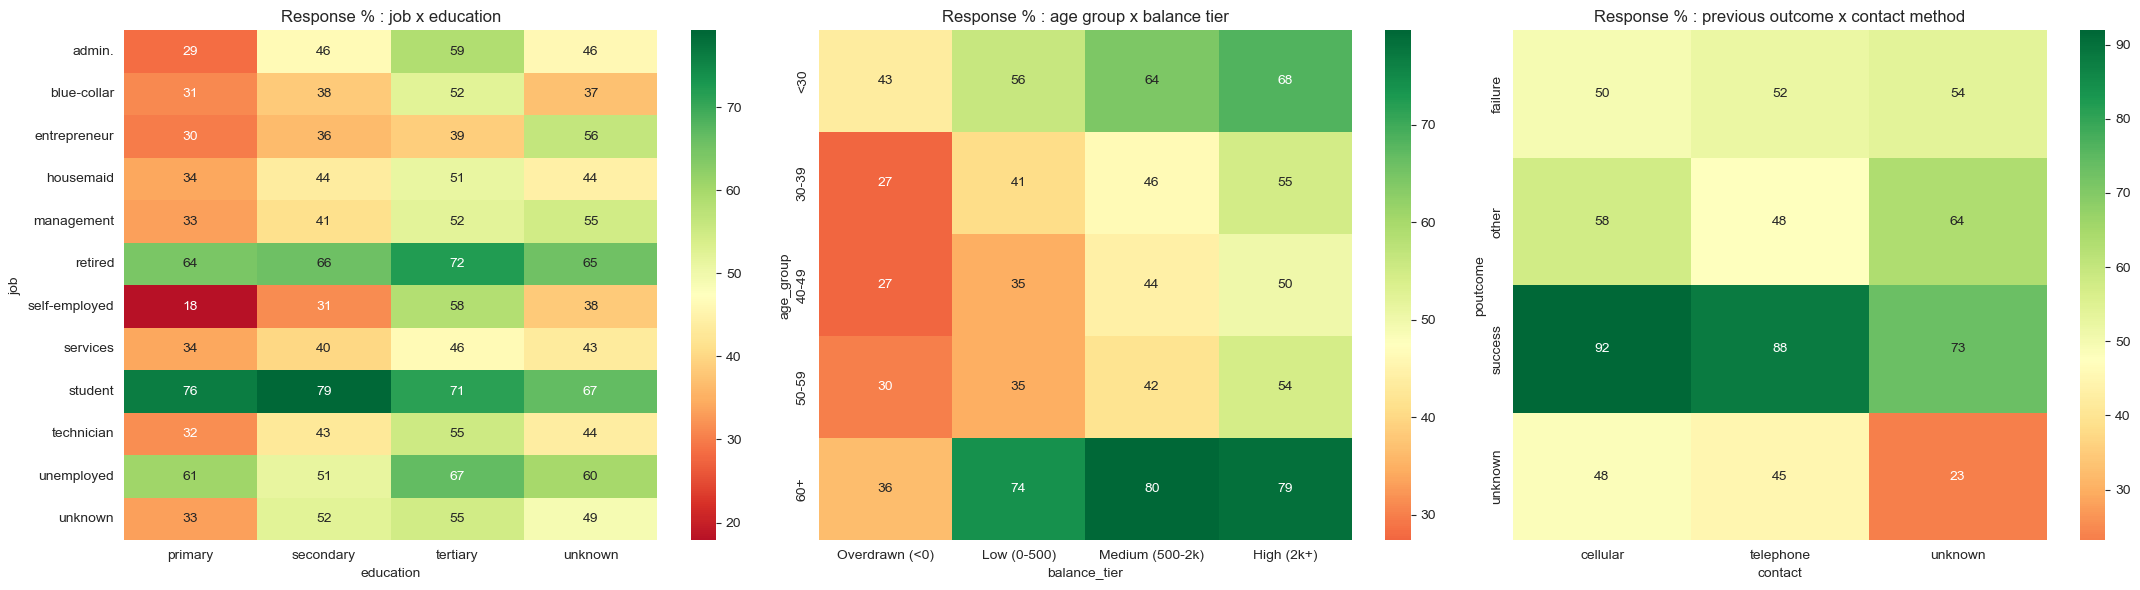

Housing x personal loan x deposit (response %, customers):
              response_%  customers
housing loan                       
no      no          59.6       5256
        yes         35.0        625
yes     no          37.6       4446
        yes         31.7        835


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
p1 = df.pivot_table(index='job', columns='education', values='deposit_flag', aggfunc='mean') * 100
sns.heatmap(p1, annot=True, fmt='.0f', cmap='RdYlGn', center=BASE, ax=axes[0]); axes[0].set_title('Response % : job x education')
p2 = df.pivot_table(index='age_group', columns='balance_tier', values='deposit_flag', aggfunc='mean', observed=True) * 100
sns.heatmap(p2, annot=True, fmt='.0f', cmap='RdYlGn', center=BASE, ax=axes[1]); axes[1].set_title('Response % : age group x balance tier')
p3 = df.pivot_table(index='poutcome', columns='contact', values='deposit_flag', aggfunc='mean') * 100
sns.heatmap(p3, annot=True, fmt='.0f', cmap='RdYlGn', center=BASE, ax=axes[2]); axes[2].set_title('Response % : previous outcome x contact method')
plt.tight_layout(); plt.show()
print('Housing x personal loan x deposit (response %, customers):')
print(df.groupby(['housing', 'loan'])['deposit_flag'].agg(['mean', 'size']).assign(mean=lambda x: (x['mean'] * 100).round(1)).rename(columns={'mean': 'response_%', 'size': 'customers'}))

**Observation**
* **Job × education:** within almost every job, tertiary education responds better than primary (e.g. admin. 59% vs 29%; self-employed 58% vs 18%). Retirees (64–72%) and students (67–79%) respond well at every education level.
* **Age × balance:** within every age band, higher balance means higher response; the overdrawn column is the weakest almost everywhere (27–43%, 36% for 60+). The 60+ group with a positive balance reaches **74–80%**; under-30s reach 56–68%.
* **Previous outcome × contact method:** a previous success converts at 92% (cellular) and 88% (telephone); customers with *no history and unknown contact* are the weakest cell at **23%**.
* **Housing × personal loan:** no loans 59.6%; housing only 37.6%; personal only 35.0%; both **31.7%**.

**Interpretation:** the effects of education, balance and loan status are not just one variable in disguise: each one still separates customers *within* the other groups. Some heatmap cells rest on few customers (for example self-employed with primary education), so extreme cell values should be read as indicative only.

**Business insight:** the best-looking segment combines a positive history, no loan burden and a healthy balance; the weakest combines no history, unknown contact method and debt. These two ends define the top and bottom of a call-priority list.

## 5. Group-based analysis

In [10]:
g = (df.groupby('job')
       .agg(customers=('customer_id', 'size'), response_rate=('deposit_flag', lambda s: s.mean() * 100),
            median_age=('age', 'median'), median_balance=('balance', 'median'),
            median_call_sec=('duration', 'median'), avg_contacts=('campaign', 'mean'))
       .round(1).sort_values('response_rate', ascending=False))
g['rank'] = g.response_rate.rank(ascending=False).astype(int)
g['vs_baseline_pts'] = (g.response_rate - BASE).round(1)
print(g.to_string())

               customers  response_rate  median_age  median_balance  median_call_sec  avg_contacts  rank  vs_baseline_pts
job                                                                                                                      
student              356           74.7        25.0           521.5            255.0           2.1     1             27.3
retired              771           66.4        63.0          1084.0            293.0           2.1     2             19.0
unemployed           357           56.6        40.0           622.0            312.0           2.1     3              9.2
management          2544           50.7        38.0           616.5            254.0           2.6     4              3.3
unknown              170           50.0        42.5           578.0            252.5           2.5     5              2.6
admin.              1326           47.3        38.0           479.0            232.0           2.4     6             -0.1
technician          1803

**Observation:** students (74.7%, +27.3 points over baseline, 356 customers) and retirees (66.4%, +19.0, 771 customers) rank first; blue-collar (36.1%, −11.3) and entrepreneurs (37.6%, −9.8) rank last. Management is the biggest group (2,544 customers) and sits slightly above baseline (50.7%). Median call length is similar across jobs (206–312 s), so the gap in response is *not* explained by calls simply being longer.

**Interpretation:** responsive groups are those that likely have idle savings and fewer commitments (students, retirees, unemployed), while groups with heavier commitments or irregular income respond less. Median balances are low everywhere (about 420–1,080), so job differences are not just wealth differences.

**Business insight:** blue-collar customers are 17% of contacts but convert at only 36%, and they cost more per subscriber (section 14). They are the largest pool where the offer or the channel may need to change.

## 6. Pivot table analysis

In [11]:
print('Pivot 1: response rate % - month (rows) x contact method (columns)')
pv1 = (df.pivot_table(index='month', columns='contact', values='deposit_flag', aggfunc='mean', observed=True) * 100).round(1)
print(pv1.to_string())
print('\nPivot 2: median balance - job x deposit outcome')
print(df.pivot_table(index='job', columns='deposit', values='balance', aggfunc='median').round(0).to_string())
print('\nPivot 3: customers and response % - previous outcome x debt status')
pv3 = df.pivot_table(index='poutcome', columns='debt_status', values='deposit_flag', aggfunc=['size', 'mean'])
pv3['mean'] = (pv3['mean'] * 100).round(1)
print(pv3.to_string())

Pivot 1: response rate % - month (rows) x contact method (columns)
contact  cellular  telephone  unknown
month                                
jan          41.9       31.6    100.0
feb          57.7       48.7     62.5
mar          89.8       88.0    100.0
apr          61.8       63.9    100.0
may          48.3       31.0     18.7
jun          84.0       74.1     25.3
jul          43.1       32.8     31.5
aug          44.9       58.2     38.7
sep          87.0       80.6     27.3
oct          81.5       87.5     80.8
nov          41.4       44.8     75.0
dec          95.5       73.7     50.0

Pivot 2: median balance - job x deposit outcome
deposit           no     yes
job                         
admin.         419.0   602.0
blue-collar    431.0   551.0
entrepreneur   342.0   606.0
housemaid      302.0   976.0
management     446.0   886.0
retired        600.0  1388.0
self-employed  467.0   810.0
services       381.0   473.0
student        490.0   551.0
technician     428.0   700.0
unem

**Observation**
* **Month × contact:** cellular is the top-converting channel in most months; unknown-contact records do very poorly in May (18.7%), June (25.3%) and July (31.5%). Values like 100% in January, March and April for `unknown` contact come from a handful of customers (3–14 per month) and should be ignored.
* **Median balance by job and outcome:** subscribers have a higher median balance than non-subscribers in every job, with large gaps for housemaids (976 vs 302), retirees (1,388 vs 600) and entrepreneurs (606 vs 342).
* **Previous outcome × debt:** a previous success converts at 86–93% regardless of debt; for customers with no history, debt-free customers convert at 51.1% against 29.5–32.7% for indebted ones.

**Interpretation:** balance is consistently higher among subscribers, confirming the financial-capacity story. A good history overrides debt, whereas for new customers debt is a strong dampener.

**Business insight:** for first-time customers, screen out or de-prioritise indebted prospects; for previous successes, debt status barely matters, so call them regardless.

## 7. Crosstab analysis

In [11]:
for a, b in [('contact', 'deposit'), ('poutcome', 'deposit'), ('debt_status', 'deposit'), ('education', 'job')]:
    if (a, b) == ('education', 'job'):
        print(f'\nCrosstab {a} x {b} - row % (who works where):')
        print((pd.crosstab(df[a], df[b], normalize='index') * 100).round(0).astype(int).to_string())
    else:
        ct = pd.crosstab(df[a], df[b], margins=True)
        print(f'\nCrosstab {a} x {b} (counts):'); print(ct.to_string())
        print(f'Row % ({a} -> share saying yes/no):'); print((pd.crosstab(df[a], df[b], normalize="index") * 100).round(1).to_string())


Crosstab contact x deposit (counts):
deposit      no   yes    All
contact                     
cellular   3647  4324   7971
telephone   380   388    768
unknown    1846   577   2423
All        5873  5289  11162
Row % (contact -> share saying yes/no):
deposit      no   yes
contact              
cellular   45.8  54.2
telephone  49.5  50.5
unknown    76.2  23.8

Crosstab poutcome x deposit (counts):
deposit     no   yes    All
poutcome                   
failure    607   605   1212
other      228   302    530
success     92   971   1063
unknown   4946  3411   8357
All       5873  5289  11162
Row % (poutcome -> share saying yes/no):
deposit     no   yes
poutcome            
failure   50.1  49.9
other     43.0  57.0
success    8.7  91.3
unknown   59.2  40.8

Crosstab debt_status x deposit (counts):
deposit                    no   yes    All
debt_status                               
Housing + personal loan   570   265    835
Housing loan only        2776  1670   4446
No loans              

**Observation**
* **Contact × deposit:** of 2,423 `unknown`-contact customers, **1,846 (76.2%) said no**, against 45.8% no for cellular.
* **Previous outcome × deposit:** of 1,063 previous successes, **971 (91.3%)** said yes. Of 8,357 customers with no history, 3,411 (40.8%) said yes, which still makes this the *largest source of subscribers* (about 64% of all 5,289).
* **Debt × deposit:** 59.6% of debt-free customers subscribe vs 31.7–37.6% of those with a loan.
* **Education × job:** 58% of tertiary-educated customers are managers; 46% of primary-educated customers are blue-collar.

**Interpretation:** job and education are linked, so part of what looks like an "education effect" may be a "job effect". Most subscribers come from customers with no history simply because they are the bulk of the base; a high *rate* in a small group (previous successes) is not the same as a high *count*.

**Business insight:** two different strategies are needed: a **retention-style call list** of previous successes (high rate, small group) and a **targeted acquisition list** among new customers (large group, lower rate, where selection by debt and balance matters most).

## 8. Advanced pandas analysis

In [13]:
# 1) Merge: attach each customer's segment benchmark (job x housing response rate) so individuals can be compared with their peer group
seg = (df.groupby(['job', 'housing']).agg(seg_customers=('customer_id', 'size'), seg_response=('deposit_flag', lambda s: s.mean() * 100)).round(1).reset_index())
df_seg = df.merge(seg, on=['job', 'housing'], how='left')
print('merge check - rows unchanged:', len(df_seg) == len(df), '| nulls in seg_response:', df_seg.seg_response.isna().sum())

# 2) Filter + sort + rank: segments with enough customers to be trustworthy (>= 100)
big = seg[seg.seg_customers >= 100].sort_values('seg_response', ascending=False)
# 3) Concat: best 5 and worst 5 reliable segments in one view
best_worst = pd.concat([big.head(5).assign(group='Top 5'), big.tail(5).assign(group='Bottom 5')], ignore_index=True)
print('\nTop and bottom reliable job x housing segments (>=100 customers):'); print(best_worst.to_string(index=False))

# 4) Rank inside each month: which contact method wins every month?
cm = df.groupby(['month', 'contact'], observed=True)['deposit_flag'].agg(['size', 'mean']).reset_index()
cm = cm[cm['size'] >= 50]; cm['rate'] = (cm['mean'] * 100).round(1)
cm['rank_in_month'] = cm.groupby('month', observed=True)['rate'].rank(ascending=False).astype(int)
print('\nContact methods ranked within each month (months/methods with >= 50 customers):')
print(cm[cm.rank_in_month == 1][['month', 'contact', 'size', 'rate']].to_string(index=False))

merge check - rows unchanged: True | nulls in seg_response: 0

Top and bottom reliable job x housing segments (>=100 customers):
          job housing  seg_customers  seg_response    group
      student      no            306          80.1    Top 5
      retired      no            648          71.0    Top 5
   unemployed      no            245          66.1    Top 5
   management      no           1481          58.1    Top 5
       admin.      no            592          57.8    Top 5
self-employed     yes            172          38.4 Bottom 5
   unemployed     yes            112          35.7 Bottom 5
     services     yes            563          32.9 Bottom 5
  blue-collar     yes           1306          32.7 Bottom 5
 entrepreneur     yes            164          32.3 Bottom 5

Contact methods ranked within each month (months/methods with >= 50 customers):
month   contact  size  rate
  jan  cellular   303  41.9
  feb  cellular   690  57.7
  mar  cellular   244  89.8
  apr telephone   

**What was used and why:** `merge` (attach each customer's job × housing benchmark so individuals can be compared with their peer group; row count unchanged and no unmatched keys), `groupby` + `agg` for segment statistics, filtering (segments with at least 100 customers only, so rates are trustworthy), sorting, ranking within months, and `concat` to put best and worst segments side by side.

**Observation:** the strongest reliable segments are students without a housing loan (80.1%, 306 customers), retirees without a housing loan (71.0%, 648) and unemployed without a housing loan (66.1%). The weakest are entrepreneurs with a housing loan (32.3%, 164) and blue-collar workers with a housing loan (**32.7%, 1,306**). Cellular is the best-converting contact method in 8 of 12 months; telephone wins April, August, October and November, but only on 55–87 customers each.

**Interpretation / insight:** housing-loan status splits almost every job into a high and a low segment, and the weakest *large* segment (blue-collar with a housing loan) is about 12% of all contacts. Cellular should be the default channel; the telephone wins are too small to act on.

## 9. Correlation and relationship analysis

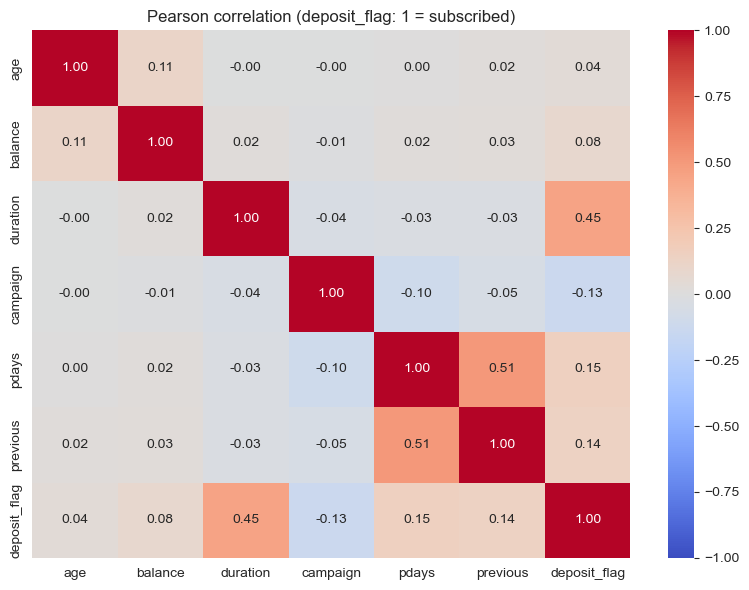

Correlation with deposit_flag, strongest first:
duration    0.449
pdays       0.152
previous    0.140
campaign   -0.128
balance     0.082
age         0.036

Spearman (rank-based, robust to skew):
duration    0.524
previous    0.230
pdays       0.213
balance     0.156
campaign   -0.127
age        -0.011

pdays vs previous: 0.51


In [12]:
num = df[['age', 'balance', 'duration', 'campaign', 'pdays', 'previous', 'deposit_flag']]
corr = num.corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Pearson correlation (deposit_flag: 1 = subscribed)'); plt.tight_layout(); plt.show()
print('Correlation with deposit_flag, strongest first:'); print(corr['deposit_flag'].drop('deposit_flag').sort_values(key=abs, ascending=False).round(3).to_string())
sp = df[['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']].corrwith(df.deposit_flag, method='spearman')
print('\nSpearman (rank-based, robust to skew):'); print(sp.round(3).sort_values(key=abs, ascending=False).to_string())
print('\npdays vs previous:', round(corr.loc['pdays', 'previous'], 2))

**Observation:** correlation with the outcome flag, strongest first: `duration` **+0.45** (Spearman +0.52), `pdays` +0.15, `previous` +0.14, `campaign` **−0.13**, `balance` +0.08, `age` +0.04 (Spearman −0.01). `pdays` and `previous` correlate at +0.51.

**Interpretation:** duration is the only moderate relationship; all others are weak. The rank-based (Spearman) coefficients are larger for duration, `previous` and `balance` because the raw variables are heavily skewed. Age's near-zero linear correlation hides its U-shaped pattern (section 3.3). `pdays` and `previous` partly measure the same thing (previous contact history).

**Business insight:** no single numeric variable predicts response well on its own except duration, which is known only after the call. Pre-call targeting therefore has to combine several weak signals (history, debt, balance, contact method), which is why the segment views above matter more than any one correlation. Correlation here is *not* causation.

## 10. Campaign performance analysis

Previously contacted vs not:
                      customers  response_rate_pct
previously_contacted                              
Yes                        2838               67.1
No                         8324               40.7

Among previously contacted: response by recency of last contact
         customers  response_rate_pct
recency                              
<=3 mo         329               76.3
3-6 mo         950               71.6
6-12 mo       1307               60.1
>1 yr          252               74.6

Among previously contacted: response by number of earlier contacts
            customers  response_rate_pct
prev_count                              
1                 887               65.7
2                 693               65.8
3-4               679               68.5
5+                579               69.3


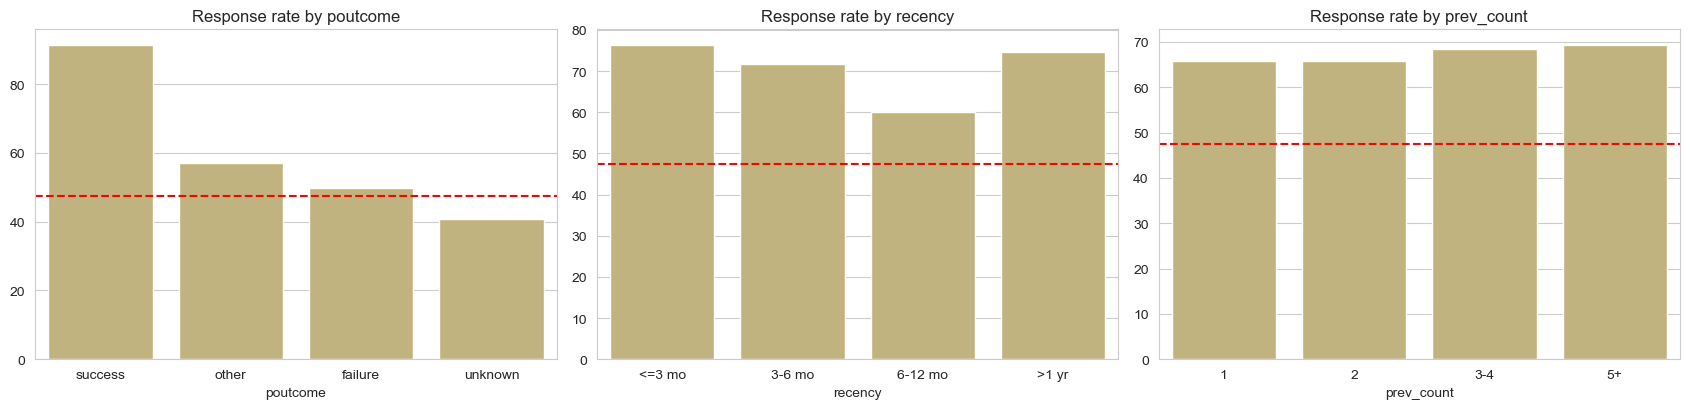

In [13]:
df['previously_contacted'] = np.where(df.pdays > -1, 'Yes', 'No')
print('Previously contacted vs not:'); print(rate_table('previously_contacted').to_string())
pc = df[df.pdays > -1].copy()
pc['recency'] = pd.cut(pc.pdays, [-1, 90, 180, 365, np.inf], labels=['<=3 mo', '3-6 mo', '6-12 mo', '>1 yr'])
print('\nAmong previously contacted: response by recency of last contact'); print(rate_table('recency', pc).reindex(['<=3 mo', '3-6 mo', '6-12 mo', '>1 yr']).to_string())
pc['prev_count'] = pd.cut(pc.previous, [0, 1, 2, 4, np.inf], labels=['1', '2', '3-4', '5+'])
print('\nAmong previously contacted: response by number of earlier contacts'); print(rate_table('prev_count', pc).reindex(['1', '2', '3-4', '5+']).to_string())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (c, data, order) in zip(axes, [('poutcome', df, None), ('recency', pc, ['<=3 mo', '3-6 mo', '6-12 mo', '>1 yr']), ('prev_count', pc, ['1', '2', '3-4', '5+'])]):
    t = rate_table(c, data); t = t.reindex(order) if order else t
    sns.barplot(x=t.index.astype(str), y=t.response_rate_pct.values, ax=ax, color='#CCB974'); ax.axhline(BASE, color='red', ls='--'); ax.set_title(f'Response rate by {c}')
plt.tight_layout(); plt.show()

**Observation:** customers contacted in an earlier campaign respond at **67.1%** vs **40.7%** for new customers. Among previously contacted customers, response is highest when the last contact was within 3 months (76.3%) and lowest at 6–12 months (60.1%); it is not a smooth decline, as customers last contacted more than a year ago respond at 74.6% (252 customers, so less reliable). The number of earlier contacts hardly matters (65.7% for one contact to 69.3% for five or more).

**Interpretation:** having a prior relationship is what matters, not how many times the customer was called before. The recency pattern is irregular, so it should not be over-read.

**Business insight:** existing relationships are a **26-point response advantage**; the 2,838 previously contacted customers are the cheapest conversions. Together with sections 3.3 and 3.4, the campaign-behaviour picture is: more calls to the same customer and more volume in a month are both linked to *lower* conversion.

## 11. Customer segment analysis

age_group             debt_status  customers  response_rate  median_balance  vs_baseline_pts
      60+                No loans        660           79.4          1230.0             32.0
      <30                No loans        760           75.9           572.0             28.5
    30-39                No loans       1772           55.5           596.0              8.1
    50-59                No loans        987           52.1           810.0              4.7
    40-49                No loans       1077           49.9           660.0              2.5
      <30       Housing loan only        582           43.5           382.0             -3.9
    30-39       Housing loan only       2057           38.2           495.0             -9.2
    40-49       Housing loan only       1137           35.3           551.0            -12.1
    30-39      Personal loan only        198           34.8           234.0            -12.6
    50-59      Personal loan only        151           31.8           

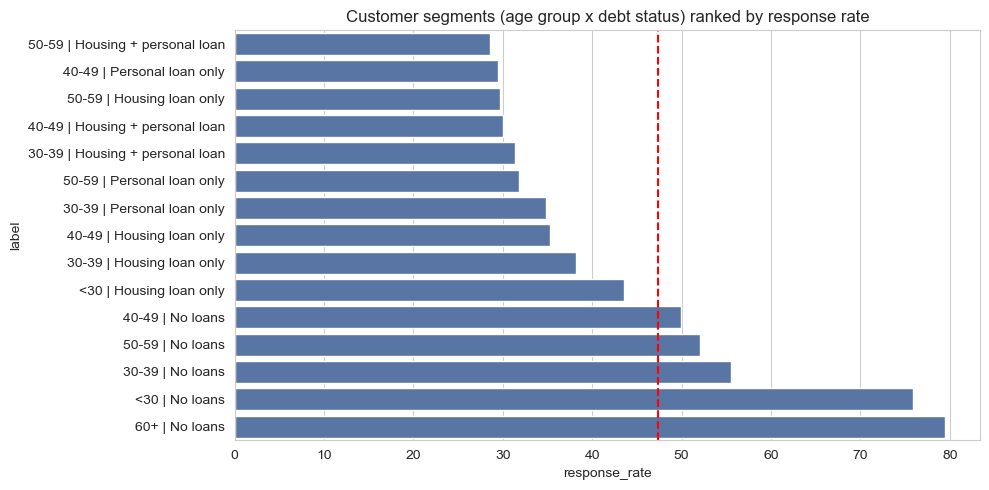

In [14]:
segs = (df.groupby(['age_group', 'debt_status'], observed=True)
          .agg(customers=('customer_id', 'size'), response_rate=('deposit_flag', lambda s: s.mean() * 100), median_balance=('balance', 'median'))
          .round(1).reset_index().query('customers >= 100').sort_values('response_rate', ascending=False))
segs['vs_baseline_pts'] = (segs.response_rate - BASE).round(1)
print(segs.to_string(index=False))
plt.figure(figsize=(10, 5))
s2 = segs.assign(label=segs.age_group.astype(str) + ' | ' + segs.debt_status).sort_values('response_rate')
sns.barplot(data=s2, x='response_rate', y='label', color='#4C72B0'); plt.axvline(BASE, color='red', ls='--')
plt.title('Customer segments (age group x debt status) ranked by response rate'); plt.tight_layout(); plt.show()

**Observation** (segments with at least 100 customers): the best segments are debt-free **60+ (79.4%, 660 customers)** and debt-free **under-30 (75.9%, 760)**. Every debt-free age group is above baseline (49.9–79.4%), while every group with a loan sits below it (28.6–43.5%). The weakest segment is **50–59 with housing and personal loans (28.6%)**, closely followed by 50–59 with only a housing loan (29.7%, 585 customers).

**Interpretation:** debt status separates customers more clearly than age does, and age matters mostly at the two ends of life (students / young adults and retirees). Customers aged 40–59 who carry loans are the least responsive.

**Business insight:** a simple two-factor rule (debt-free, plus very young or retired) isolates a group that responds at roughly 75–80%, versus 47% overall. Debt-laden mid-life customers need a different offer rather than more calls.

## 12–13. Visualization and visual storytelling
Every chart above is followed by an Observation / Interpretation / Business-insight block. The visual story, in order: *who the customers are* (sections 1–2) → *who responds* (3, 5, 11) → *how combinations behave* (4, 6, 7, 9) → *how the campaign itself behaves* (3.4, 10) → *what it costs* (sections 14–15).

## 14. ROI module A — customer-level cost and value (assumption-based proxy)

> **Read this first.** The dataset has no real cost or revenue fields. The numbers below use two *assumed* constants: **0.50 per minute of call** and **200 per subscriber**. They are illustrative. Because value is fixed at 200 per subscriber, the ranking of segments by "net value per contact" is mostly the **response rate** adjusted for **call time**; it does **not** show real profitability. Treat the **cost per subscriber** column as the most useful figure, since it depends only on the cost assumption and the observed calls.

ASSUMPTIONS (illustrative, not bank financials): cost 0.50/min of call, value 200 per subscriber
Total proxy cost 34,462 | total proxy value 1,057,800 | overall proxy ROI 2,970%
Share of call-time cost spent on customers who said NO: 31.7%
Avg cost per subscriber: 6.52

--- proxy ROI by contact ---
           customers  subscribers  total_cost  total_value  net_value  roi_pct  cost_per_subscriber  net_value_per_contact
contact                                                                                                                   
cellular        7971         4324     24880.0     864800.0   839920.0   3376.0                 5.75                  105.4
telephone        768          388      2234.0      77600.0    75366.0   3374.0                 5.76                   98.1
unknown         2423          577      7348.0     115400.0   108052.0   1470.0                12.74                   44.6

--- proxy ROI by duration_band ---
               customers  subscribers  total_cost

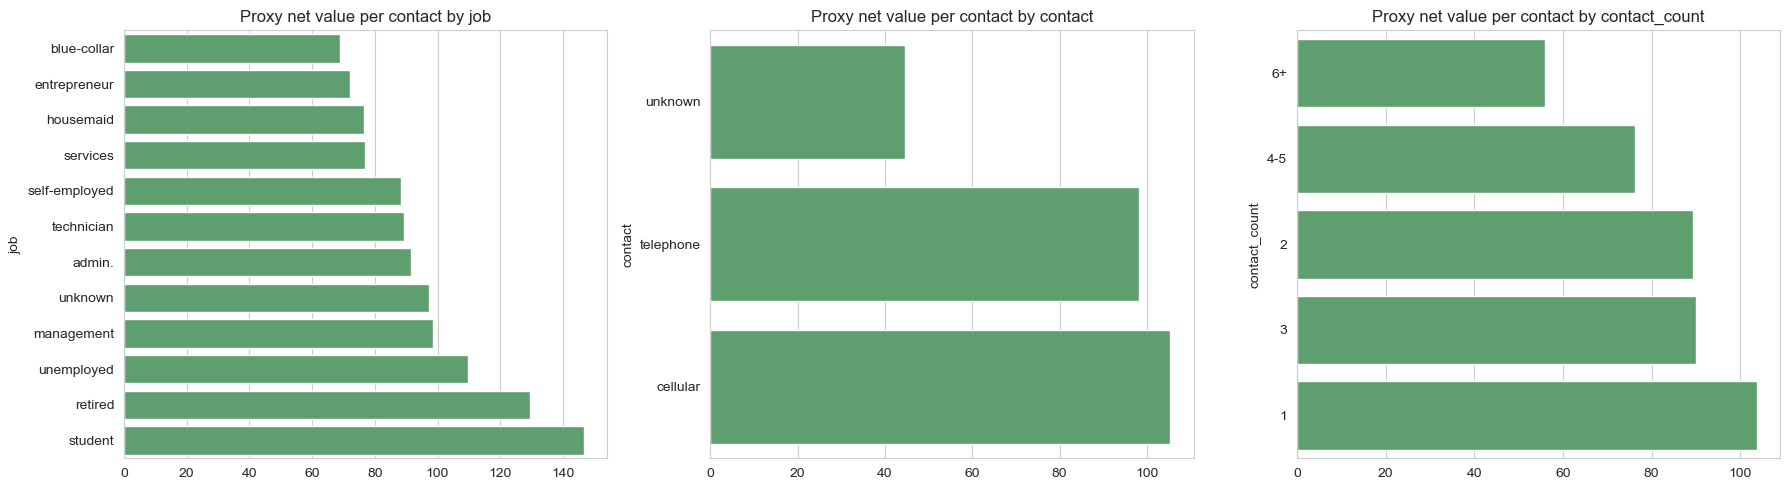

In [15]:
def roi_table(col, data=df, min_n=50):
    t = data.groupby(col, observed=True).agg(customers=('customer_id', 'size'), subscribers=('deposit_flag', 'sum'),
            total_cost=('estimated_campaign_cost', 'sum'), total_value=('estimated_deposit_value', 'sum'), net_value=('estimated_net_value', 'sum'))
    t = t[t.customers >= min_n]
    t['roi_pct'] = ((t.total_value - t.total_cost) / t.total_cost * 100).round(0)
    t['cost_per_subscriber'] = (t.total_cost / t.subscribers).round(2)
    t['net_value_per_contact'] = (t.net_value / t.customers).round(1)
    return t.round({'total_cost': 0, 'total_value': 0, 'net_value': 0, 'roi_pct': 0, 'cost_per_subscriber': 2, 'net_value_per_contact': 1}).sort_values('net_value_per_contact', ascending=False)

tot_cost, tot_val = df.estimated_campaign_cost.sum(), df.estimated_deposit_value.sum()
wasted = df.loc[df.deposit == 'no', 'estimated_campaign_cost'].sum()
print(f'ASSUMPTIONS (illustrative, not bank financials): cost 0.50/min of call, value 200 per subscriber')
print(f'Total proxy cost {tot_cost:,.0f} | total proxy value {tot_val:,.0f} | overall proxy ROI {(tot_val - tot_cost) / tot_cost * 100:,.0f}%')
print(f'Share of call-time cost spent on customers who said NO: {wasted / tot_cost * 100:.1f}%')
print(f'Avg cost per subscriber: {tot_cost / df.deposit_flag.sum():.2f}')
for c in ['contact', 'duration_band', 'contact_count', 'poutcome', 'job']:
    print(f'\n--- proxy ROI by {c} ---'); print(roi_table(c).to_string())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ['job', 'contact', 'contact_count']):
    t = roi_table(c).sort_values('net_value_per_contact')
    sns.barplot(x=t.net_value_per_contact.values, y=t.index.astype(str), ax=ax, color='#55A868'); ax.set_title(f'Proxy net value per contact by {c}')
plt.tight_layout(); plt.show()

**Observation**
* Under the assumptions, total proxy cost is 34,462 and total proxy value is 1,057,800 (overall proxy ROI 2,970%; this number is a product of the assumed 200 value and is not a real return). Average cost per subscriber is **6.52**.
* **31.7% of all call-time cost is spent on customers who said no.**
* **Contact method:** cellular and telephone cost about 5.75 per subscriber; **unknown-contact customers cost 12.74**, more than double.
* **Call length:** cost per subscriber is lowest in the 2–5 minute band (4.25) and highest for 10+ minute calls (9.30), even though 10+ minute calls convert at 85%; calls under 2 minutes are cheap per call (6.57 per subscriber) but only 9.3% convert, so they yield the least net value per contact (18 vs 78–162 in the longer bands).
* **Contacts:** cost per subscriber climbs from 5.61 (one call) to **9.17 (6+ calls)**.
* **History:** previous successes cost 3.16 per subscriber vs 7.75 for customers with no history.
* **Job:** students (3.68) and retirees (4.86) are the cheapest to convert; blue-collar (9.05) and entrepreneurs (8.11) the most expensive.

**Interpretation:** the segments that respond most are also the cheapest to convert, so targeting and cost efficiency point the same way. The cost of repeated calls (6+) is about 63% higher per subscriber than a single call.

**Business insight:** the largest avoidable cost is calling unknown-contact and no-history customers repeatedly with little chance of success. The bank should replace the assumed 0.50 / 200 with its own real cost per call-minute and value per deposit, which can be done by editing the two constants in the Sprint 1 ROI step and re-running; the segment *ranking* is likely to stay similar but the absolute ROI numbers will change.

## 15. ROI module B — real campaign performance table (88 campaigns, analysed separately)

This table (`Spend`, `Clicks`, `Revenue`) comes from marketing channels such as Email, PPC and Referral, whereas the bank file records *telephone* contact. There is no shared key and the channel names differ, so **the two are not joined**. Section 14 and section 15 answer different questions and should not be added together.

Cleaning steps (each follows Problem → Action → Reason): 5 campaigns have **no channel** → kept as `Unknown` instead of guessing; the supplied `ROI %` is stored as a ratio (4.29 = 429%) → recomputed as (Revenue − Spend) / Spend × 100 and checked against the supplied value (max difference 0.05 points); no duplicate IDs and all dates parsed.

Shape: (88, 7)
Campaign_ID                  object
Date                 datetime64[ns]
Marketing_channel            object
Spend                       float64
Clicks                        int64
Revenue                     float64
ROI %                       float64

Missing Values:
Campaign_ID          0
Date                 0
Marketing_channel    5
Spend                0
Clicks               0
Revenue              0
ROI %                0

Duplicate Campaign IDs: 0
Unparsed Dates: 0
Max | Recomputed ROI - Supplied ROI |: 0.05

Channel-wise Analysis:
                   campaigns    spend   revenue  clicks  median_campaign_roi  mean_campaign_roi  pooled_roi_pct  revenue_per_click
Marketing_channel                                                                                                                 
Social Media              16  39045.0  187032.0   17766                380.0              596.0           379.0              10.53
Ppc                       22  52139.0  236061.0  

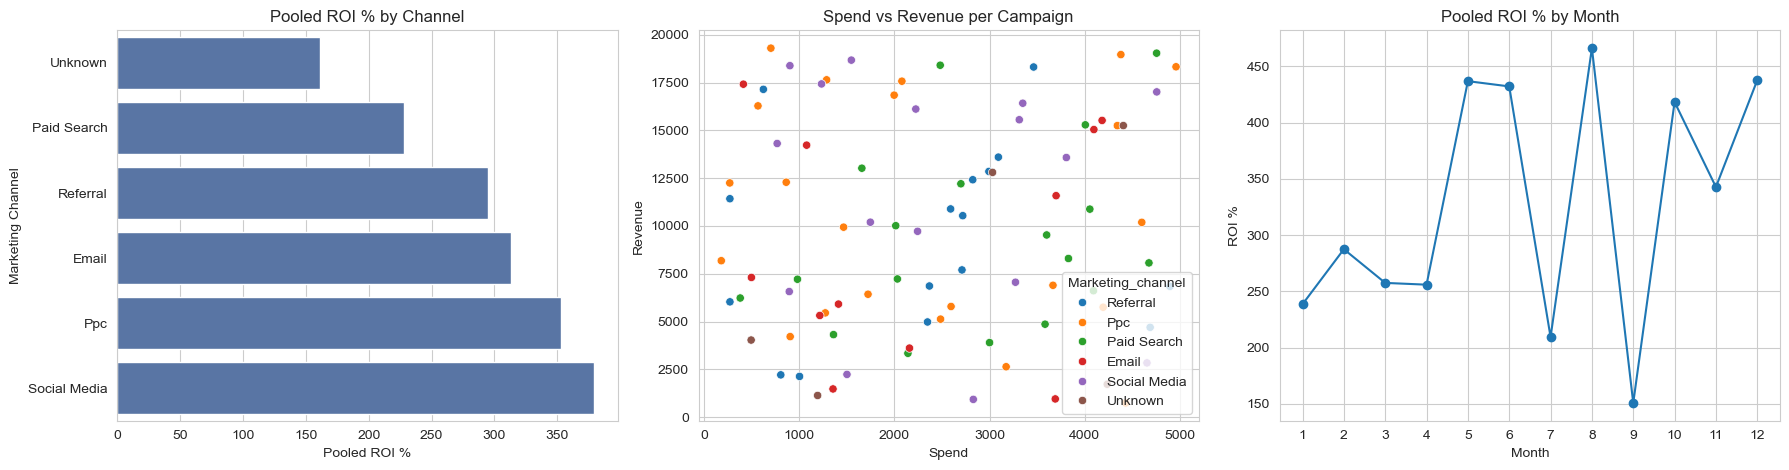

In [18]:
# 1. Load dataset
camp = pd.read_excel(
    f'{DATA_DIR}/Marketing Campaign Performance and ROI Dataset.xlsx',
    sheet_name='Marketing Campaign Performance '
)

# 2. Data inspection
camp.columns = camp.columns.str.strip()

print('Shape:', camp.shape)
print(camp.dtypes.to_string())

print('\nMissing Values:')
print(camp.isna().sum().to_string())

print('\nDuplicate Campaign IDs:',
      camp.Campaign_ID.duplicated().sum())

# 3. Date conversion
camp['Date'] = pd.to_datetime(camp['Date'], errors='coerce')

print('Unparsed Dates:', camp.Date.isna().sum())

# 4. Handle missing values
camp['Marketing_channel'] = camp['Marketing_channel'].fillna('Unknown')

# 5. Calculate ROI
camp['roi_calc_pct'] = (
    (camp['Revenue'] - camp['Spend']) / camp['Spend'] * 100
).round(1)

# Compare calculated ROI with supplied ROI
roi_diff = (
    camp['roi_calc_pct'] - camp['ROI %'] * 100
).abs().max()

print(
    'Max | Recomputed ROI - Supplied ROI |:',
    round(roi_diff, 2)
)

# 6. Extract month
camp['month'] = camp.Date.dt.month

# 7. Channel-wise analysis
ch = camp.groupby('Marketing_channel').agg(
    campaigns=('Campaign_ID', 'size'),
    spend=('Spend', 'sum'),
    revenue=('Revenue', 'sum'),
    clicks=('Clicks', 'sum'),
    median_campaign_roi=('roi_calc_pct', 'median'),
    mean_campaign_roi=('roi_calc_pct', 'mean')
).round(0)

# Calculate pooled ROI
ch['pooled_roi_pct'] = (
    (ch.revenue - ch.spend) / ch.spend * 100
).round(0)

# Revenue per click
ch['revenue_per_click'] = (
    ch.revenue / ch.clicks
).round(2)

print('\nChannel-wise Analysis:')
print(ch.sort_values(
    'pooled_roi_pct',
    ascending=False
).to_string())

# 8. Correlation analysis
print(
    '\nCorrelations:',
    'Spend-Revenue:', round(camp.Spend.corr(camp.Revenue), 2),
    '| Clicks-Revenue:', round(camp.Clicks.corr(camp.Revenue), 2),
    '| Spend-ROI:', round(camp.Spend.corr(camp.roi_calc_pct), 2)
)

# 9. Loss-making campaigns
loss_campaigns = (camp.roi_calc_pct < 0).sum()

print(
    '\nLoss-making campaigns (ROI < 0):',
    loss_campaigns,
    'of',
    len(camp)
)

# 10. Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Chart 1: Pooled ROI by channel
t = ch.sort_values('pooled_roi_pct')

sns.barplot(
    x=t.pooled_roi_pct.values,
    y=t.index,
    ax=axes[0],
    color='#4C72B0'
)

axes[0].set_title('Pooled ROI % by Channel')
axes[0].set_xlabel('Pooled ROI %')
axes[0].set_ylabel('Marketing Channel')

# Chart 2: Spend vs Revenue
sns.scatterplot(
    data=camp,
    x='Spend',
    y='Revenue',
    hue='Marketing_channel',
    ax=axes[1]
)

axes[1].set_title('Spend vs Revenue per Campaign')

# Chart 3: Monthly Pooled ROI
mm = camp.groupby('month').agg(
    spend=('Spend', 'sum'),
    revenue=('Revenue', 'sum')
)

monthly_roi = (
    (mm.revenue - mm.spend) / mm.spend * 100
)

axes[2].plot(
    mm.index,
    monthly_roi,
    marker='o'
)

axes[2].set_title('Pooled ROI % by Month')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('ROI %')
axes[2].set_xticks(mm.index)

# Display all charts
plt.tight_layout()
plt.show()


**Observation**
* **Pooled ROI by channel** (total revenue vs total spend): Social Media **379%**, PPC 353%, Email 313%, Referral 295%, Paid Search **228%**; the five campaigns with no channel return 161%.
* Revenue per click: Social Media 10.53, PPC 10.44, Paid Search 9.85, Referral 9.70, **Email 7.57**.
* The simple *average* of campaign ROI is much higher than the pooled figure (PPC 966% vs 353%) because a few campaigns with tiny spend produce enormous ratios.
* **Spend vs revenue correlation is only +0.06; clicks vs revenue is −0.03; spend vs ROI is −0.62.** 7 of 88 campaigns lost money.

**Interpretation:** spending more, or earning more clicks, did *not* produce more revenue in this table. ROI falls as spend rises partly because the ratio is mechanically inflated for small-spend campaigns. Pooled ROI and median ROI are more trustworthy than the simple mean.

**Business insight:** budget should not be allocated just by raising spend or chasing clicks. Paid Search has the lowest pooled ROI of the named channels and Email the lowest revenue per click, so these are the first to review. With only 11–22 campaigns per channel, these channel differences are **not yet shown to be statistically real**; that is a Sprint 3 test (e.g. ANOVA / Kruskal–Wallis on campaign ROI).

## 16. Business insights summary

### Customer characteristics and segments
* The best responders are **debt-free customers who are either 60+ (79%) or under 30 (76%)**, students (75%) and retirees (66%). The weakest are customers aged 40–59 with loans (roughly 29–35%) and blue-collar customers with a housing loan (32.7%, 1,306 customers).
* Financial capacity matters: response climbs from 30.5% (overdrawn) to 57.8% (balance above 2,000), and from 31.7% (housing + personal loan) to 59.6% (no loans).

### Campaign behaviour
* **Previous success → 91% conversion**; any previous contact → 67% vs 41% for new customers.
* **Unknown contact method → 24%** (vs 54% cellular), but this is tangled with May and June, where 92% of those records sit.
* **More than 3 calls to one customer is linked to lower conversion** (about 40% at 4–5 calls, 29% at 6+).
* The busiest month (May, 25% of volume) has the lowest response (32.8%).

### Cost view
* Under the stated assumptions, 31.7% of call-time cost goes to customers who say no; cost per subscriber is roughly 1.6–2.5 times higher for unknown-contact customers (12.74 vs about 5.75), 6+ calls (9.17 vs 5.61 for one call) and blue-collar customers (9.05 vs 3.68 for students) than for the efficient segments.
* From the real campaign table, Social Media and PPC have the highest pooled ROI and Paid Search the lowest among named channels, with spend and clicks showing almost no relationship with revenue.

### Limits of this sprint
* All findings are associations from observational data; none is yet tested for statistical significance.
* `duration` cannot be used for pre-call targeting.
* Several segments are small (default = yes with 168 customers, December with 110, `unknown` job with 170) and some heatmap cells rest on few customers.
* The ROI proxy depends on two assumed constants; the campaign-level ROI is not linked to customers.

### Carry-forward to Sprint 3
1. **Chi-square** tests: contact method, previous outcome, housing/loan status vs deposit.
2. **t-test / Mann–Whitney**: balance and duration between subscribers and non-subscribers (both are heavily skewed).
3. **ANOVA / Kruskal–Wallis**: response or balance across jobs; ROI across marketing channels.
4. **Confidence intervals** for the 47.4% response rate and for key segment rates.
5. **Feature engineering**: age group, debt status, contact-frequency band, previously-contacted flag, balance tier (the bands used here are the prototypes), with a before/after evaluation.

## Task coverage map (Sprint 2 brief → where it is done)
| Brief item | Section |
|---|---|
| 1 Descriptive analysis | 1 |
| 2 Univariate | 2 |
| 3 Bivariate | 3 |
| 4 Multivariate | 4 |
| 5 Group-based analysis | 5 |
| 6 Pivot tables | 6 |
| 7 Crosstabs | 7 |
| 8 Advanced pandas (merge, groupby, filter, sort, rank, concat) | 0, 5, 8 |
| 9 Correlation | 9 |
| 10 Campaign performance | 3.4, 10, 15 |
| 11 Customer segments | 11 |
| 12–13 Visualization and storytelling | all charts + sections 12–13 |
| 14 Business insights | 16 |
| Extension: ROI (proxy and real campaign table) | 14, 15 |